# Proyek Klasifikasi Gambar: Lung Cancer Histopathological
- **Nama:** Anggi Maulana
- **Email:** anggimaulana23@student.polindra.ac.id
- **ID Dicoding:** anggi_maulana_07

## Import Semua Packages/Library yang Digunakan

In [ ]:
!pip install --no-deps -q tensorflowjs==4.22.0


In [32]:
!pip install -q tensorflow-decision-forests

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.2/15.2 MB 57.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
ERROR: Could not find a version that satisfies the requirement tensorflow~=2.15.0 (from tensorflow-decision-forests) (from versions: 2.20.0rc0, 2.20.0, 2.21.0rc0, 2.21.0rc1, 2.21.0, 2.22.0rc0)
ERROR: No matching distribution found for tensorflow~=2.15.0


In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [ ]:
# Verifikasi package/API yang akan dipakai saat ekspor TFJS (tanpa menjalankan konversi).
import importlib.metadata as metadata
import sys

print("Python:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)
try:
    import tensorflowjs as tfjs
    from tensorflowjs.converters import save_keras_model
    tfjs_version = metadata.version("tensorflowjs")
    print("TensorFlow.js:", tfjs_version)
    print("API save_keras_model: tersedia")
    if sys.version_info >= (3, 13) and tfjs_version == "4.22.0":
        print("PERINGATAN: tensorflowjs 4.22.0 pada Python 3.13 memiliki laporan kompatibilitas di sejumlah environment.")
        print("Jika import atau ekspor gagal, jangan menganggap model TFJS berhasil dibuat; gunakan traceback yang muncul.")
except Exception as e:
    print("API TensorFlow.js belum siap:", repr(e))
    print("Periksa output instalasi cell sebelumnya sebelum menjalankan konversi.")


Python: 3.13.15
TensorFlow: 2.21.0
API TensorFlow.js belum siap: ModuleNotFoundError("No module named 'tensorflow_decision_forests'")
Periksa output instalasi cell sebelumnya sebelum menjalankan konversi.


In [ ]:
# Import libraries
import os, shutil
import zipfile
import random
from random import sample
import shutil
from shutil import copyfile
import pathlib
from pathlib import Path
import numpy as np
import pandas as pd
from tqdm.notebook import tqdm as tq
import tensorflow as tf

# Visualisasi
%matplotlib inline
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.image import imread

# Image processing
import cv2
from PIL import Image
import skimage
from skimage import io
from skimage.transform import resize

# Model & Training
import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
from tensorflow.keras import Model, layers
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, load_img
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.layers import InputLayer, Conv2D, SeparableConv2D, MaxPooling2D, MaxPool2D, Dense, Flatten, Dropout, BatchNormalization
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.callbacks import ModelCheckpoint, Callback, EarlyStopping, ReduceLROnPlateau

from collections import Counter

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

## Data Preparation

### Data Loading

In [ ]:
# Kredensial Kaggle jangan ditulis langsung di notebook.
# Di Google Colab, simpan sebagai Secrets bernama KAGGLE_USERNAME dan KAGGLE_KEY.
# Di lingkungan lain, isi environment variable dengan nama yang sama.
import os
from getpass import getpass

try:
    from google.colab import userdata
    kaggle_username = userdata.get("KAGGLE_USERNAME")
    kaggle_key = userdata.get("KAGGLE_KEY")
except Exception:
    kaggle_username = os.environ.get("KAGGLE_USERNAME")
    kaggle_key = os.environ.get("KAGGLE_KEY")

# Jika tidak ditemukan di Secrets/Env, minta input interaktif agar sel tidak error
if not kaggle_username:
    print("KAGGLE_USERNAME tidak ditemukan di Secrets.")
    kaggle_username = input("Masukkan Kaggle Username Anda: ").strip()

if not kaggle_key:
    print("KAGGLE_KEY tidak ditemukan di Secrets.")
    kaggle_key = getpass("Masukkan Kaggle API Key Anda: ").strip()

if not kaggle_username or not kaggle_key:
    raise RuntimeError(
        "Kredensial Kaggle belum diisi. Harap masukkan username dan API key "
        "melalui prompt atau tambahkan ke Colab Secrets."
    )

os.environ["KAGGLE_USERNAME"] = kaggle_username
os.environ["KAGGLE_KEY"] = kaggle_key
print("Kredensial Kaggle berhasil dibaca dan dikonfigurasi (nilai disembunyikan).")

Kredensial Kaggle berhasil dibaca dan dikonfigurasi (nilai disembunyikan).


In [ ]:
# Download kaggle dataset and unzip the file
!kaggle datasets download -d rm1000/lung-cancer-histopathological-images

Dataset URL: https://www.kaggle.com/datasets/rm1000/lung-cancer-histopathological-images
License(s): CC-BY-SA-4.0
100% 1.55G/1.55G [00:22<00:00, 74.1MB/s]



In [ ]:
!unzip lung-cancer-histopathological-images.zip

Output streaming akan dipotong hingga 5000 baris terakhir.
  inflating: squamous_cell_carcinoma/0000.jpg  
  inflating: squamous_cell_carcinoma/0001.jpg  
  inflating: squamous_cell_carcinoma/0002.jpg  
  inflating: squamous_cell_carcinoma/0003.jpg  
  inflating: squamous_cell_carcinoma/0004.jpg  
  inflating: squamous_cell_carcinoma/0005.jpg  
  inflating: squamous_cell_carcinoma/0006.jpg  
  inflating: squamous_cell_carcinoma/0007.jpg  
  inflating: squamous_cell_carcinoma/0008.jpg  
  inflating: squamous_cell_carcinoma/0009.jpg  
  inflating: squamous_cell_carcinoma/0010.jpg  
  inflating: squamous_cell_carcinoma/0011.jpg  
  inflating: squamous_cell_carcinoma/0012.jpg  
  inflating: squamous_cell_carcinoma/0013.jpg  
  inflating: squamous_cell_carcinoma/0014.jpg  
  inflating: squamous_cell_carcinoma/0015.jpg  
  inflating: squamous_cell_carcinoma/0016.jpg  
  inflating: squamous_cell_carcinoma/0017.jpg  
  inflating: squamous_cell_carcinoma/0018.jpg  
  inflating: squamous_cell_ca

In [ ]:
# Definisi Path
base_dir = Path("lung-cancer-histopathological-images")
combined_dir = base_dir / "dataset"
source_dirs = ["adenocarcinoma", "benign", "squamous_cell_carcinoma"]

# Buat direktori tujuan
combined_dir.mkdir(parents=True, exist_ok=True)

# Proses Penggabungan Dataset
for folder in source_dirs:
    src_path = Path(folder)
    if src_path.exists():
        dest_path = combined_dir / folder
        # Menggunakan shutil.copytree untuk menyalin seluruh folder sebagai sub-folder di 'dataset'
        if not dest_path.exists():
            shutil.copytree(src_path, dest_path)
    else:
        print(f"Peringatan: Folder {folder} tidak ditemukan.")

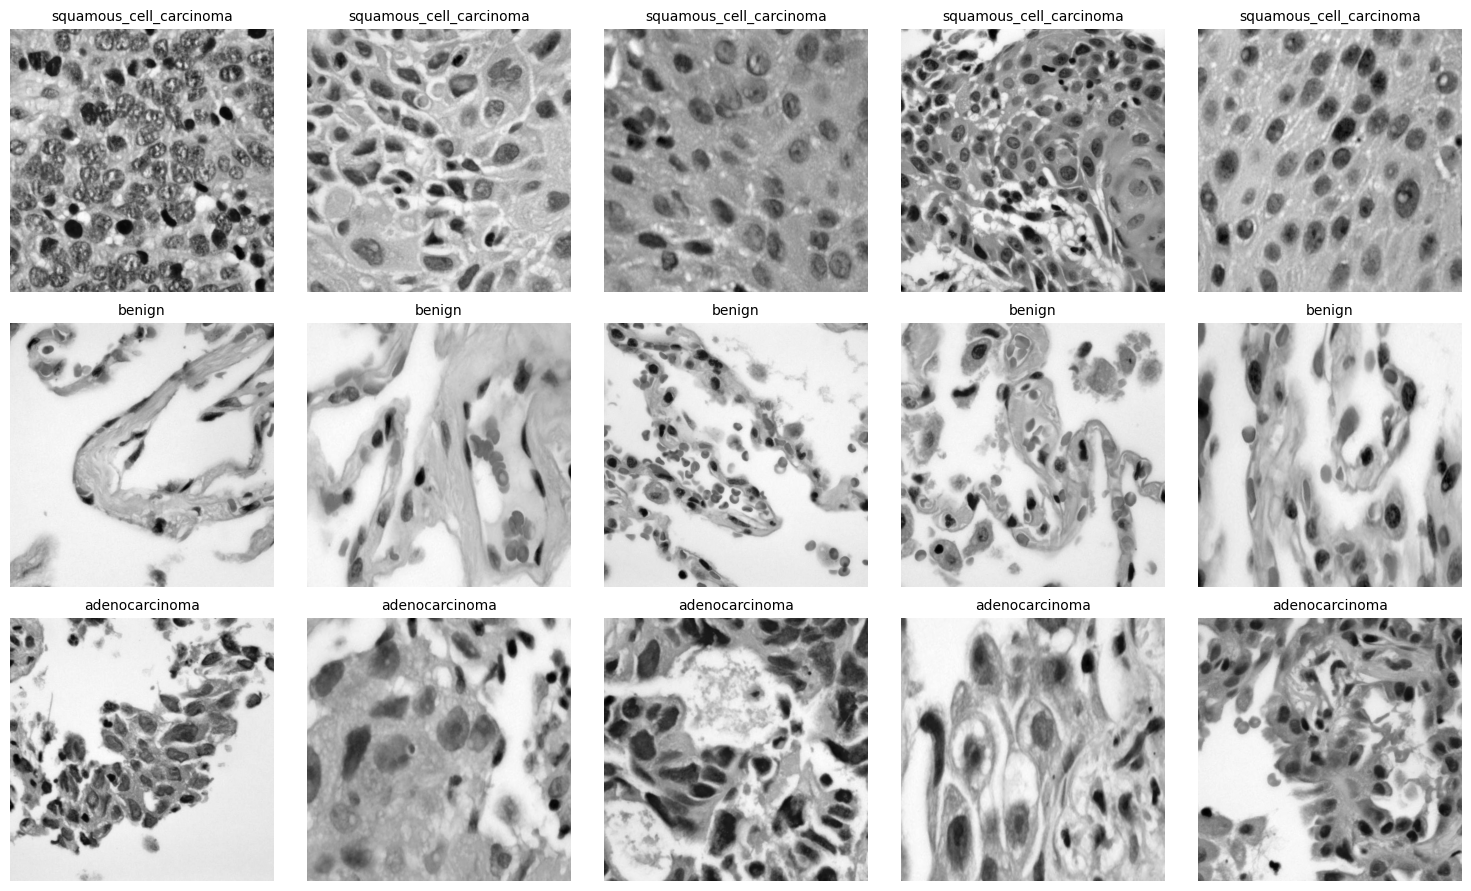

In [ ]:
# Membangun Dictionary Gambar
lung_image = {}
if combined_dir.exists():
    for class_folder in combined_dir.iterdir():
        if class_folder.is_dir():
            # Simpan list file gambar (filter hanya file)
            images = [f.name for f in class_folder.glob('*') if f.is_file()]
            if images:
                lung_image[class_folder.name] = images

# Validasi Data sebelum Visualisasi
num_classes = len(lung_image)
fig, axs = plt.subplots(num_classes, 5, figsize=(15, 3 * num_classes))

# Jika hanya ada 1 kelas, axs akan berupa array 1D, kita ubah ke 2D untuk konsistensi index [i, j]
if num_classes == 1:
    axs = np.expand_dims(axs, axis=0)

for i, (class_name, image_list) in enumerate(lung_image.items()):
    # Ambil 5 sampel secara acak
    n_samples = min(len(image_list), 5)
    selected_images = np.random.choice(image_list, n_samples, replace=False)

    for j, image_name in enumerate(selected_images):
        img_path = combined_dir / class_name / image_name
        img = Image.open(img_path).convert("L")
        axs[i, j].imshow(img, cmap='gray')
        axs[i, j].set_title(class_name, fontsize=10)
        axs[i, j].axis('off') # Menghilangkan axis untuk tampilan lebih bersih

plt.tight_layout()
plt.show()

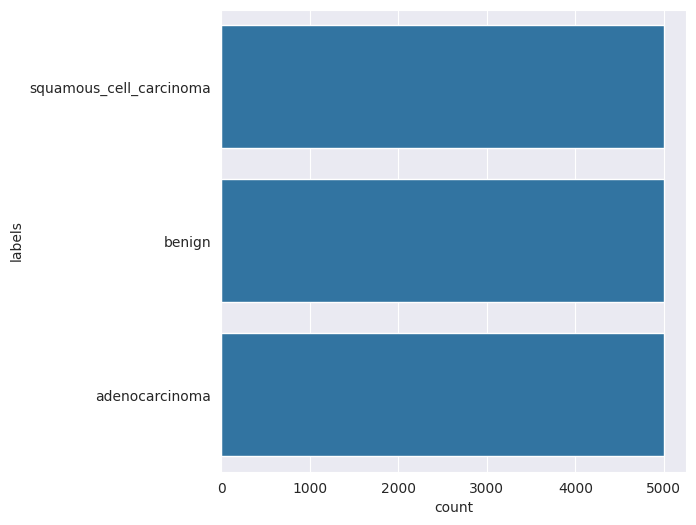

In [ ]:
# Define source path
lung_path = "lung-cancer-histopathological-images/dataset/"

# Create a list that stores data for each filenames, filepaths, and labels in the data
file_name = []
labels = []
full_path = []

# Get data image filenames, filepaths, labels one by one with looping, and store them as dataframe
for path, subdirs, files in os.walk(lung_path):
    for name in files:
        full_path.append(os.path.join(path, name))
        labels.append(path.split('/')[-1])
        file_name.append(name)

distribution_train = pd.DataFrame({"path":full_path,'file_name':file_name,"labels":labels})

# Plot the distribution of images across the classes
Label = distribution_train['labels']
plt.figure(figsize = (6,6))
sns.set_style("darkgrid")
plot_data = sns.countplot(Label)
plt.show()

Jumlah resolusi unik yang ditemukan: 1

Top 10 resolusi paling sering muncul:
  768x768 px -> 15000 gambar


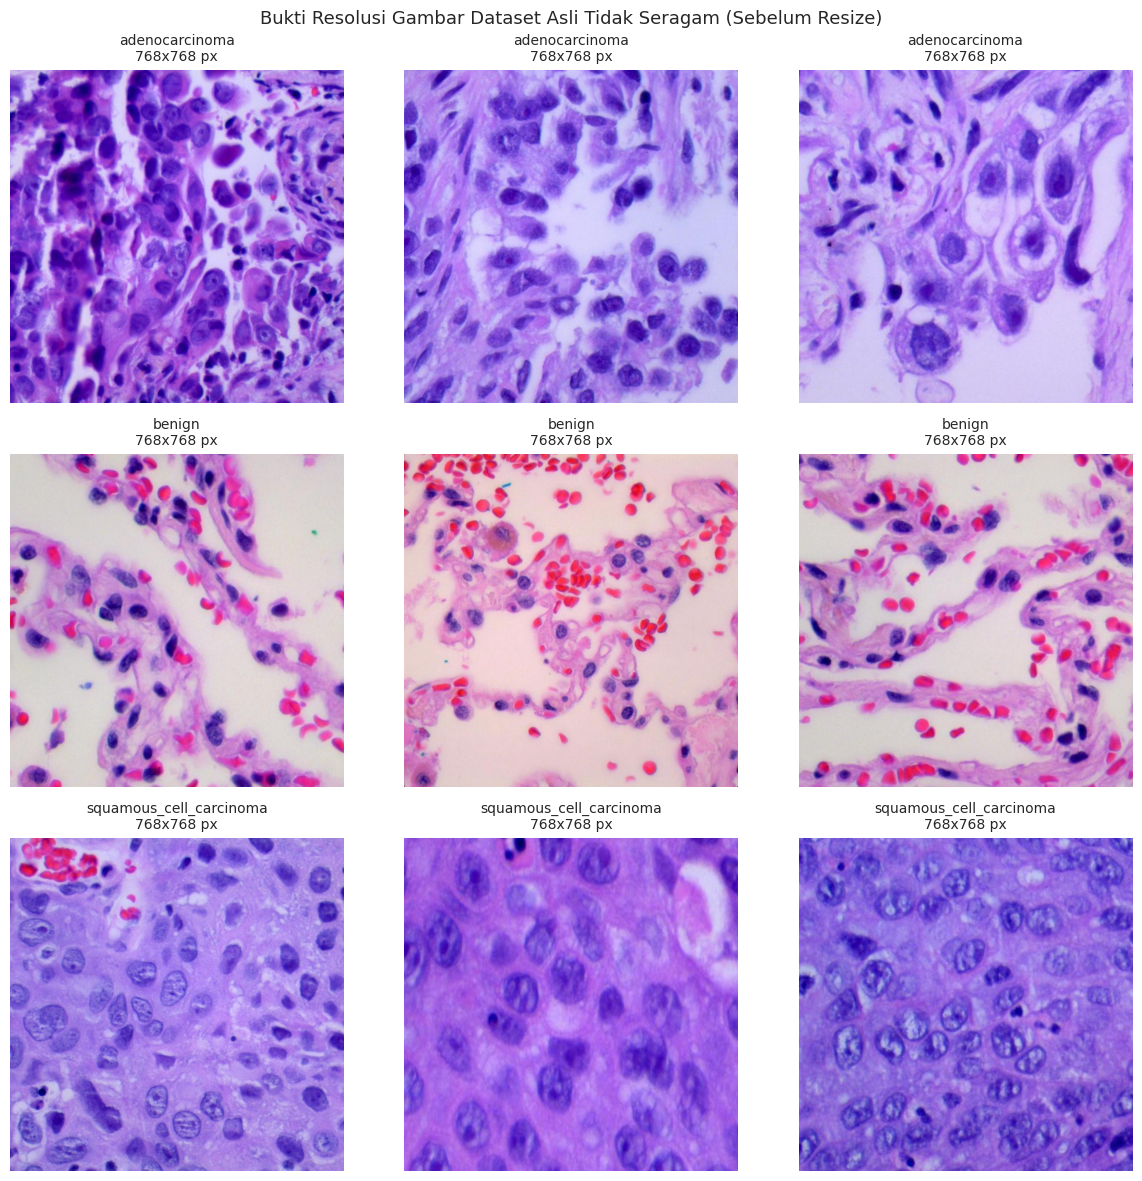

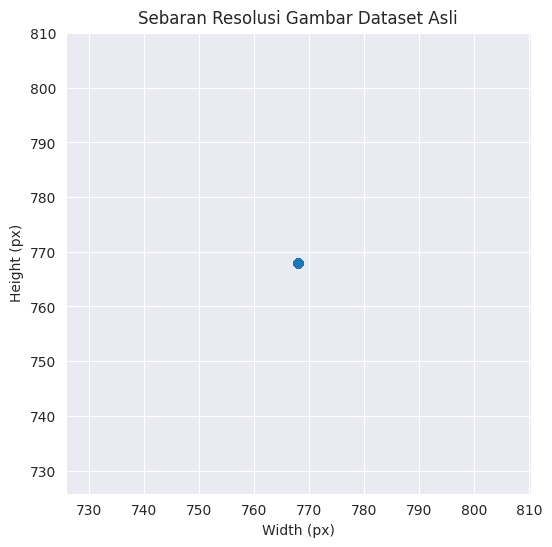

In [ ]:
image_shapes = []
sample_display = []

for class_name in source_dirs:
    class_path = combined_dir / class_name
    image_files = list(class_path.glob('*'))
    for img_path in image_files:
        with Image.open(img_path) as img:
            image_shapes.append(img.size)  # (width, height)
    sample_display.append((class_name, list(np.random.choice(image_files, 3, replace=False))))

shape_counter = Counter(image_shapes)
print(f"Jumlah resolusi unik yang ditemukan: {len(shape_counter)}")
print("\nTop 10 resolusi paling sering muncul:")
for shape, count in shape_counter.most_common(10):
    print(f"  {shape[0]}x{shape[1]} px -> {count} gambar")

# Tampilkan sampel gambar asli beserta resolusinya
fig, axs = plt.subplots(len(source_dirs), 3, figsize=(12, 4 * len(source_dirs)))
for i, (class_name, files) in enumerate(sample_display):
    for j, img_path in enumerate(files):
        img = Image.open(img_path)
        axs[i, j].imshow(img, cmap='gray')
        axs[i, j].set_title(f"{class_name}\n{img.size[0]}x{img.size[1]} px", fontsize=10)
        axs[i, j].axis('off')
plt.suptitle("Bukti Resolusi Gambar Dataset Asli Tidak Seragam (Sebelum Resize)", fontsize=13)
plt.tight_layout()
plt.show()

# Sebaran width x height seluruh dataset
widths = [s[0] for s in image_shapes]
heights = [s[1] for s in image_shapes]
plt.figure(figsize=(6, 6))
plt.scatter(widths, heights, alpha=0.4)
plt.xlabel("Width (px)")
plt.ylabel("Height (px)")
plt.title("Sebaran Resolusi Gambar Dataset Asli")
plt.show()

### Data Preprocessing

#### Split Dataset

In [ ]:
SOURCE_PATH = 'lung-cancer-histopathological-images/dataset/'
FINAL_DATASET_DIR = "Dataset-Final/"
IMG_SIZE = (150, 150)
BATCH_SIZE = 32

# Mengumpulkan path dan label secara rekursif
file_paths = []
labels = []

for root, dirs, files in os.walk(SOURCE_PATH):
    for name in files:
        if name.lower().endswith(('.png', '.jpg', '.jpeg')):
            file_paths.append(os.path.join(root, name))
            labels.append(os.path.basename(root))

df = pd.DataFrame({"path": file_paths, "labels": labels})

In [ ]:
# Pisahkan 20% untuk TEST
X_train_val, X_test, y_train_val, y_test = train_test_split(
    df['path'], df['labels'], test_size=0.2, random_state=300, stratify=df['labels']
)

# Pisahkan 20% dari Train_Val untuk VALIDATION
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.2, random_state=300, stratify=y_train_val
)

# Masukkan ke DataFrame dengan label set yang jelas
df_tr = pd.DataFrame({'path': X_train, 'labels': y_train, 'set': 'train'})
df_va = pd.DataFrame({'path': X_val, 'labels': y_val, 'set': 'val'})
df_te = pd.DataFrame({'path': X_test, 'labels': y_test, 'set': 'test'})
df_all = pd.concat([df_tr, df_va, df_te], ignore_index=True)

In [ ]:
# Copy file ke folder masing-masing
print("Memindahkan file ke folder Train, Val, dan Test...")
for _, row in tq(df_all.iterrows(), total=df_all.shape[0]):
    dest_dir = os.path.join(FINAL_DATASET_DIR, row['set'], row['labels'])
    os.makedirs(dest_dir, exist_ok=True)

    dest_file = os.path.join(dest_dir, os.path.basename(row['path']))
    if not os.path.exists(dest_file):
        shutil.copy2(row['path'], dest_file)

print(f"\nDistribusi Akhir:")
print(f"Train: {len(df_tr)}")
print(f"Val  : {len(df_va)}")
print(f"Test : {len(df_te)}")

Memindahkan file ke folder Train, Val, dan Test...


  0%|          | 0/15000 [00:00<?, ?it/s]


Distribusi Akhir:
Train: 9600
Val  : 2400
Test : 3000


In [ ]:
# Define training and test directories
TRAIN_DIR = "Dataset-Final/train/"
VAL_DIR   = "Dataset-Final/val/"
TEST_DIR  = "Dataset-Final/test/"

# Augmentasi untuk training
train_datagen = ImageDataGenerator(
    rescale=1/255.,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    zoom_range=0.15,
    fill_mode='nearest'
)

# Val dan Test tanpa augmentasi
val_datagen = ImageDataGenerator(rescale=1/255.)
test_datagen = ImageDataGenerator(rescale=1/255.)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="grayscale",
    class_mode='categorical',
    shuffle=True
)

validation_generator = val_datagen.flow_from_directory(
    VAL_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="grayscale",
    class_mode='categorical',
    shuffle=False
)

test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=1,
    color_mode="grayscale",
    class_mode='categorical',
    shuffle=False
)

print("\nData generator siap!")

Found 9600 images belonging to 3 classes.
Found 2400 images belonging to 3 classes.
Found 3000 images belonging to 3 classes.

Data generator siap!


## Modelling

In [ ]:
model = Sequential([
    # Block 1
    Conv2D(32, (3, 3), activation='relu', input_shape=(150, 150, 1)),
    BatchNormalization(),
    MaxPooling2D(2, 2),

    # Block 2
    Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2, 2),

    # Block 3
    Conv2D(128, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2, 2),

    # Block 4
    Conv2D(256, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2, 2),

    # Classifier
    Flatten(),
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(3, activation='softmax')
])

# Compile Model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 148, 148, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 72, 72, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 34, 34, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 15, 15, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 15, 15, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     6,423,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │         1,539 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,814,339 (25.99 MB)

 Trainable params: 6,813,379 (25.99 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:
# Menghentikan training jika val_loss tidak turun selama 5 epoch
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Menyimpan model terbaik secara otomatis
checkpoint = ModelCheckpoint(
    'best_lung_cancer_model.keras',
    monitor='val_accuracy',
    save_best_only=True
)

# Mengurangi Learning Rate jika progress melambat agar konvergensi lebih halus
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6)

callbacks_list = [early_stop, checkpoint, reduce_lr]

In [ ]:
# Melatih model
history = model.fit(
    train_generator,
    epochs=30,
    validation_data=validation_generator,
    callbacks=callbacks_list,
    verbose=1
)

Epoch 1/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 103s 295ms/step - accuracy: 0.7636 - loss: 1.6546 - val_accuracy: 0.3333 - val_loss: 21.9599 - learning_rate: 0.0010
Epoch 2/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 85s 282ms/step - accuracy: 0.8499 - loss: 0.3873 - val_accuracy: 0.6121 - val_loss: 4.5183 - learning_rate: 0.0010
Epoch 3/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 85s 284ms/step - accuracy: 0.8861 - loss: 0.2994 - val_accuracy: 0.5608 - val_loss: 3.5842 - learning_rate: 0.0010
Epoch 4/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 86s 288ms/step - accuracy: 0.8872 - loss: 0.3033 - val_accuracy: 0.3333 - val_loss: 57.9729 - learning_rate: 0.0010
Epoch 5/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 85s 283ms/step - accuracy: 0.8921 - loss: 0.2823 - val_accuracy: 0.5742 - val_loss: 9.0385 - learning_rate: 0.0010
Epoch 6/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 81s 271ms/step - accuracy: 0.9133 - loss: 0.2376 - val_accuracy: 0.3442 - val_loss: 34.2318 - learning_rate: 0.0010
Epoch 7/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 85s 283ms/step - accuracy:

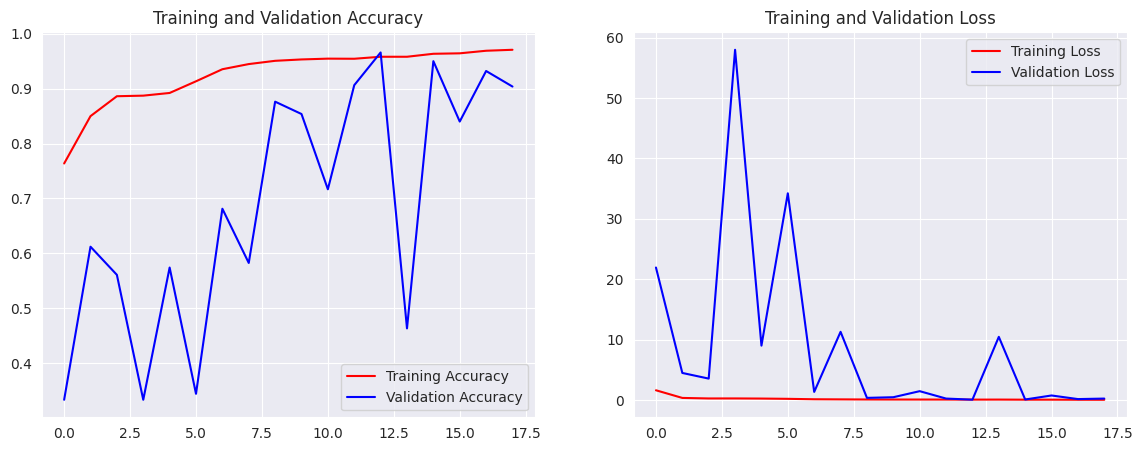

In [ ]:
# Visualisasi Plot Akurasi dan Loss
def plot_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(len(acc))

    plt.figure(figsize=(14, 5))

    # Plot Akurasi
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'r', label='Training Accuracy')
    plt.plot(epochs, val_acc, 'b', label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.legend()

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'r', label='Training Loss')
    plt.plot(epochs, val_loss, 'b', label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.legend()

    plt.show()

plot_history(history)

## Evaluasi dan Visualisasi

3000/3000 ━━━━━━━━━━━━━━━━━━━━ 22s 7ms/step
Akurasi training tertinggi tercatat: 97.07%
Akurasi testing: 96.50%


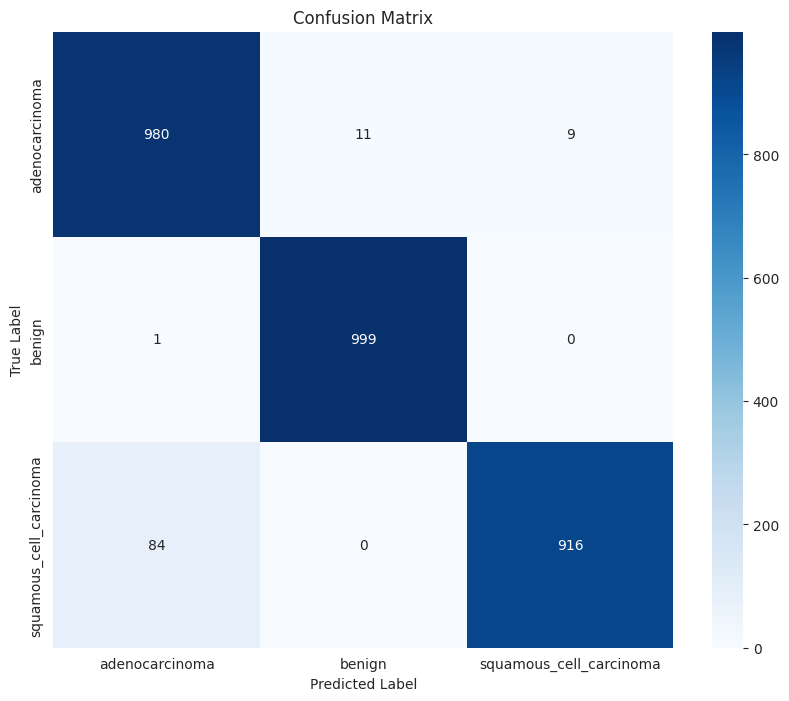


Classification Report:
                         precision    recall  f1-score   support

         adenocarcinoma     0.9202    0.9800    0.9492      1000
                 benign     0.9891    0.9990    0.9940      1000
squamous_cell_carcinoma     0.9903    0.9160    0.9517      1000

               accuracy                         0.9650      3000
              macro avg     0.9665    0.9650    0.9650      3000
           weighted avg     0.9665    0.9650    0.9650      3000



In [ ]:
# Reset generator agar evaluasi selalu berjalan dari sampel pertama.
test_generator.reset()

# Melakukan prediksi
preds = model.predict(test_generator, verbose=1)

# Mengambil index kelas dengan probabilitas tertinggi
y_pred = np.argmax(preds, axis=1)

# Mengambil label asli dari generator
y_true = test_generator.classes

# Nama kelas untuk label di plot
class_names = list(test_generator.class_indices.keys())

# Ringkasan akurasi untuk pemeriksaan kriteria submission.
train_accuracy_peak = max(history.history.get('accuracy', [0.0]))
test_accuracy = float(np.mean(y_pred == y_true))
print(f"Akurasi training tertinggi tercatat: {train_accuracy_peak:.2%}")
print(f"Akurasi testing: {test_accuracy:.2%}")
if train_accuracy_peak < 0.85:
    print("PERINGATAN: akurasi training yang tercatat belum mencapai 85%.")
if test_accuracy < 0.85:
    print("PERINGATAN: akurasi testing belum mencapai 85%; periksa model/data sebelum submission.")

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

# Classification Report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))


In [ ]:
# Error Analysis: Visualisasi Gambar yang Salah Diklasifikasikan
misclassified_idx = np.where(y_pred != y_true)[0]
print(f"Total salah klasifikasi: {len(misclassified_idx)} dari {len(y_true)} ({len(misclassified_idx)/len(y_true)*100:.2f}%)")

test_filepaths = test_generator.filepaths
n_display = min(9, len(misclassified_idx))

if n_display > 0:
    sample_errors = np.random.choice(misclassified_idx, n_display, replace=False)
    plt.figure(figsize=(15, 15))
    for i, idx in enumerate(sample_errors):
        img = Image.open(test_filepaths[idx]).convert("L")
        plt.subplot(3, 3, i + 1)
        plt.imshow(img, cmap='gray')
        plt.title(f"True: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]}", fontsize=10, color='red')
        plt.axis('off')
    plt.suptitle("Contoh Gambar yang Salah Diklasifikasikan (Error Analysis)", fontsize=14)
    plt.tight_layout()
    plt.show()
else:
    print("Tidak ada kesalahan klasifikasi pada test set.")

# Pola kesalahan: kelas mana yang paling sering tertukar
error_df = pd.DataFrame({
    'true_label': [class_names[i] for i in y_true],
    'pred_label': [class_names[i] for i in y_pred]
})
error_only = error_df[error_df['true_label'] != error_df['pred_label']]
print("\nPola kesalahan klasifikasi (true -> predicted):")
print(error_only.groupby(['true_label', 'pred_label']).size().sort_values(ascending=False))

In [ ]:
## Grad-CAM: Interpretasi Model

# Cari layer Conv2D terakhir secara otomatis (robust terhadap perubahan arsitektur)
last_conv_layer_name = [layer.name for layer in model.layers if isinstance(layer, Conv2D)][-1]
print(f"Layer Conv2D terakhir untuk Grad-CAM: {last_conv_layer_name}")

# Bangun ulang graph model secara eksplisit (fix untuk Keras 3):
# Sequential model yang dilatih lewat generator belum punya graph simbolik
# yang bisa langsung dipakai model.inputs/model.output, jadi kita rebuild
# manual dengan memanggil tiap layer di atas tf.keras.Input.
img_input = tf.keras.Input(shape=(150, 150, 1))
x = img_input
conv_output_tensor = None
for layer in model.layers:
    x = layer(x)
    if layer.name == last_conv_layer_name:
        conv_output_tensor = x

grad_model = tf.keras.models.Model(inputs=img_input, outputs=[conv_output_tensor, x])

def make_gradcam_heatmap(img_array, grad_model, pred_index=None):
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-10)
    return heatmap.numpy()

def display_gradcam(img_path, heatmap, alpha=0.4):
    img = image.load_img(img_path, target_size=(150, 150))
    img_arr = image.img_to_array(img)

    heatmap_resized = np.uint8(255 * heatmap)
    jet = plt.colormaps["jet"]
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap_resized]
    jet_heatmap = tf.keras.utils.array_to_img(jet_heatmap)
    jet_heatmap = jet_heatmap.resize((img_arr.shape[1], img_arr.shape[0]))
    jet_heatmap = tf.keras.utils.img_to_array(jet_heatmap)

    superimposed_img = jet_heatmap * alpha + img_arr
    return tf.keras.utils.array_to_img(superimposed_img)

correct_idx = np.where(y_pred == y_true)[0]
gradcam_samples = list(np.random.choice(misclassified_idx, min(2, len(misclassified_idx)), replace=False)) if len(misclassified_idx) > 0 else []
gradcam_samples += list(np.random.choice(correct_idx, min(2, len(correct_idx)), replace=False))

plt.figure(figsize=(12, 12))
for i, idx in enumerate(gradcam_samples):
    img_path = test_filepaths[idx]
    img = image.load_img(img_path, target_size=(150, 150), color_mode="grayscale")
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) / 255.0

    heatmap = make_gradcam_heatmap(img_array, grad_model, pred_index=y_pred[idx])
    superimposed = display_gradcam(img_path, heatmap)

    plt.subplot(2, 2, i + 1)
    plt.imshow(superimposed)
    status = "BENAR" if y_pred[idx] == y_true[idx] else "SALAH"
    plt.title(f"[{status}] True: {class_names[y_true[idx]]} | Pred: {class_names[y_pred[idx]]}", fontsize=10)
    plt.axis('off')

plt.suptitle("Grad-CAM: Area Gambar yang Menjadi Fokus Model", fontsize=14)
plt.tight_layout()
plt.show()

## Konversi Model

Model diekspor ke tiga format: **SavedModel**, **TensorFlow Lite**, dan **TensorFlow.js LayersModel**. Untuk TFJS, jalur Python API `save_keras_model` digunakan langsung dari model Keras karena lebih sederhana daripada menjalankan converter CLI terhadap SavedModel. Output TFJS yang valid harus memiliki `model.json` dan file bobot `.bin`; di JavaScript, format ini dimuat dengan `tf.loadLayersModel(...)`.


In [35]:
from pathlib import Path
import json
import shutil
import sys
import types
import tensorflow as tf

# Mocking tensorflow_decision_forests karena tidak didukung di TF 2.21 + Python 3.13
# dan tidak digunakan oleh model klasifikasi gambar kita.
if "tensorflow_decision_forests" not in sys.modules:
    mock_tfdf = types.ModuleType("tensorflow_decision_forests")
    sys.modules["tensorflow_decision_forests"] = mock_tfdf
    print("✓ Berhasil mem-bypass dependensi tensorflow_decision_forests dengan Mocking.")

# Gunakan checkpoint dengan val_accuracy terbaik bila tersedia agar model yang ekspor
# konsisten dengan model terbaik yang disimpan selama training.
checkpoint_path = Path("best_lung_cancer_model.keras")
if checkpoint_path.is_file():
    export_model = tf.keras.models.load_model(str(checkpoint_path))
    print(f"Model ekspor: checkpoint terbaik ({checkpoint_path})")
else:
    export_model = model
    print("PERINGATAN: checkpoint tidak ditemukan; mengekspor model dari memori saat ini.")

output_root = Path("models")
saved_model_dir = output_root / "saved_model"
tflite_dir = output_root / "tflite"
tfjs_dir = output_root / "tfjs_model"
output_root.mkdir(parents=True, exist_ok=True)

# 1. SavedModel — hapus hasil lama agar tidak tertukar dengan ekspor sebelumnya.
if saved_model_dir.exists():
    shutil.rmtree(saved_model_dir)
export_model.export(str(saved_model_dir))
if not (saved_model_dir / "saved_model.pb").is_file():
    raise RuntimeError(f"SavedModel tidak valid: saved_model.pb tidak ditemukan di {saved_model_dir}")
print(f"✓ SavedModel tersimpan: {saved_model_dir.resolve()}")

# 2. TensorFlow Lite
tflite_dir.mkdir(parents=True, exist_ok=True)
tflite_path = tflite_dir / "lung_cancer_model.tflite"
converter = tf.lite.TFLiteConverter.from_saved_model(str(saved_model_dir))
tflite_model = converter.convert()
tflite_path.write_bytes(tflite_model)
if not tflite_path.is_file() or tflite_path.stat().st_size == 0:
    raise RuntimeError("Konversi TFLite tidak menghasilkan file .tflite yang valid.")
print(f"✓ TensorFlow Lite tersimpan: {tflite_path.resolve()} ({tflite_path.stat().st_size:,} bytes)")

# 3. TensorFlow.js — gunakan API Python langsung, bukan shell command yang dapat gagal
# tanpa memicu exception Python dan tetap mencetak pesan sukses.
if tfjs_dir.exists():
    shutil.rmtree(tfjs_dir)
tfjs_dir.mkdir(parents=True, exist_ok=True)

print("Memulai ekspor TensorFlow.js LayersModel...", flush=True)
try:
    import tensorflowjs as tfjs
    tfjs.converters.save_keras_model(export_model, str(tfjs_dir))
except Exception as e:
    raise RuntimeError(
        "Ekspor TFJS gagal. Traceback di bawah ini adalah error sebenarnya dari API "
        "converter. Jangan anggap ekspor berhasil bila file model.json belum terbentuk."
    ) from e

model_json_path = tfjs_dir / "model.json"
if not model_json_path.is_file() or model_json_path.stat().st_size == 0:
    raise RuntimeError(
        f"Ekspor TFJS tidak valid: model.json tidak ditemukan atau kosong di {tfjs_dir.resolve()}"
    )

with model_json_path.open("r", encoding="utf-8") as f:
    tfjs_manifest = json.load(f)

weight_files = sorted(tfjs_dir.glob("*.bin"))
if not weight_files:
    raise RuntimeError(
        f"model.json terbentuk, tetapi file bobot .bin tidak ditemukan di {tfjs_dir.resolve()}"
    )

# Validasi bahwa semua file bobot yang direferensikan model.json benar-benar tersedia.
referenced_files = []
for group in tfjs_manifest.get("weightsManifest", []):
    referenced_files.extend(group.get("paths", []))
missing_files = [name for name in referenced_files if not (tfjs_dir / name).is_file()]
if missing_files:
    raise RuntimeError(f"File bobot TFJS hilang: {missing_files}")

print("✓ TensorFlow.js LayersModel berhasil dibuat dan diverifikasi.")
print(f"  model.json: {model_json_path.resolve()} ({model_json_path.stat().st_size:,} bytes)")
for weight_file in weight_files:
    print(f"  bobot: {weight_file.name} ({weight_file.stat().st_size:,} bytes)")
print("  Cara memuat di JavaScript: await tf.loadLayersModel('.../model.json')")

Model ekspor: checkpoint terbaik (best_lung_cancer_model.keras)
Saved artifact at 'models/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 150, 150, 1), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  133707524284944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133707524288016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133707524285136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133707524288208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133707524279760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133707524287824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133707524289552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133707524291280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133707524279184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133707524288400: Te

failed to lookup keras version from the file,
    this is likely a weight only file
✓ TensorFlow.js LayersModel berhasil dibuat dan diverifikasi.
  model.json: /content/models/tfjs_model/model.json (13,118 bytes)
  bobot: group1-shard1of7.bin (4,194,304 bytes)
  bobot: group1-shard2of7.bin (4,194,304 bytes)
  bobot: group1-shard3of7.bin (4,194,304 bytes)
  bobot: group1-shard4of7.bin (4,194,304 bytes)
  bobot: group1-shard5of7.bin (4,194,304 bytes)
  bobot: group1-shard6of7.bin (4,194,304 bytes)
  bobot: group1-shard7of7.bin (2,091,532 bytes)
  Cara memuat di JavaScript: await tf.loadLayersModel('.../model.json')


## Inference (Optional)

Model berhasil dimuat


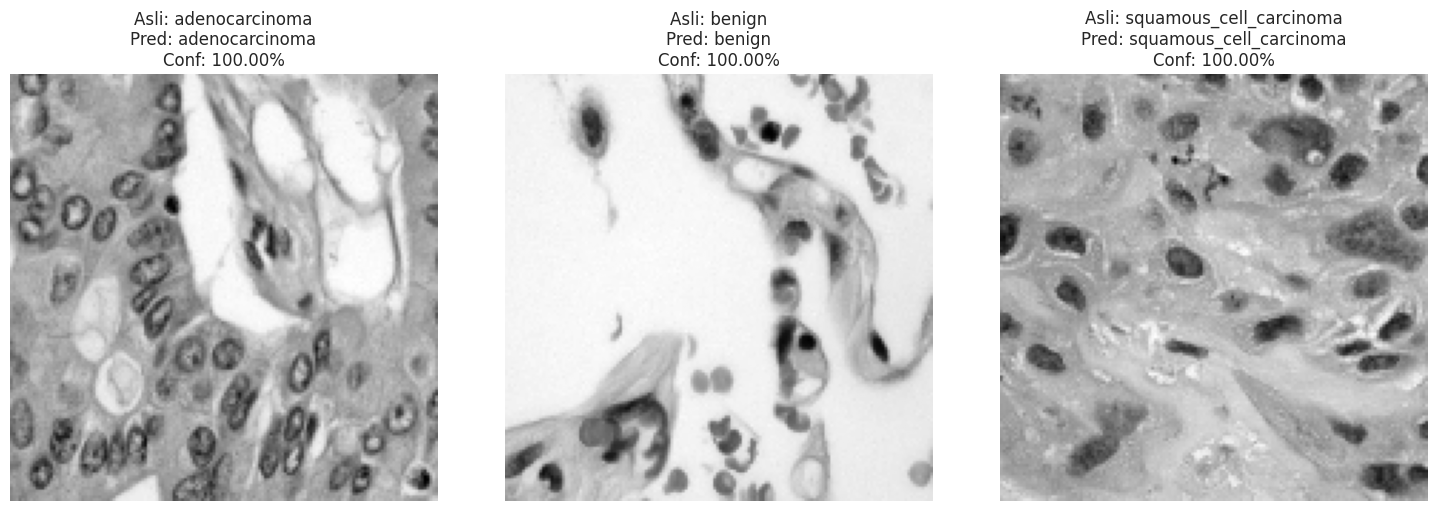


Selesai!


In [37]:
# Load model terbaik
loaded_model = tf.keras.models.load_model('best_lung_cancer_model.keras')
print("Model berhasil dimuat")

class_indices = test_generator.class_indices
labels_map = {v: k for k, v in class_indices.items()}

plt.figure(figsize=(15, 5))

for i, (cls_name, cls_idx) in enumerate(class_indices.items()):
    specific_class_path = os.path.join(TEST_DIR, cls_name)

    available_files = [f for f in os.listdir(specific_class_path)
                       if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

    img_name = np.random.choice(available_files)
    full_img_path = os.path.join(specific_class_path, img_name)

    # Load dan preprocess
    img = image.load_img(full_img_path, target_size=(150, 150), color_mode="grayscale")
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) / 255.0

    # Prediksi
    pred = loaded_model.predict(img_array, verbose=0)[0]
    pred_idx = np.argmax(pred)
    conf = pred[pred_idx] * 100

    # Visualisasi
    plt.subplot(1, 3, i+1)
    plt.imshow(img, cmap='gray')
    plt.title(f"Asli: {cls_name}\nPred: {labels_map[pred_idx]}\nConf: {conf:.2f}%")
    plt.axis('off')

plt.tight_layout()
plt.show()

print("\nSelesai!")

In [41]:
from pathlib import Path
import shutil

# Folder target yang terlihat di screenshot kamu
output_root = Path("/content/models")
tflite_dir = output_root / "tflite"
tfjs_dir = output_root / "tfjs_model"

# 1. Pastikan hasil TFJS yang baru benar-benar tersedia
assert (tfjs_dir / "model.json").is_file(), \
    "model.json tidak ditemukan di models/tfjs_model"

assert list(tfjs_dir.glob("*.bin")), \
    "File bobot TFJS tidak ditemukan"

# 2. Ganti nama file TFLite sesuai ketentuan Dicoding
old_tflite = tflite_dir / "lung_cancer_model.tflite"
new_tflite = tflite_dir / "model.tflite"

if old_tflite.is_file() and not new_tflite.exists():
    old_tflite.rename(new_tflite)

assert new_tflite.is_file(), \
    "model.tflite tidak ditemukan"

# 3. Buat label.txt dari pemetaan kelas yang digunakan saat training
class_indices = test_generator.class_indices

if class_indices != train_generator.class_indices:
    raise ValueError("Pemetaan kelas train dan test tidak konsisten.")

labels = [
    name for name, index in sorted(
        class_indices.items(),
        key=lambda item: item[1]
    )
]

label_path = tflite_dir / "label.txt"
label_path.write_text("\n".join(labels) + "\n", encoding="utf-8")

# 4. Tampilkan lokasi hasil akhir
print("Lokasi output:", output_root.resolve())
print("SavedModel:", (output_root / "saved_model").is_dir())
print("TFJS:", tfjs_dir.is_dir())
print("TFLite:", new_tflite.is_file())
print("Label:", label_path.is_file())
print("\nLabel kelas:")
for i, label in enumerate(labels):
    print(f"{i}: {label}")

Lokasi output: /content/models
SavedModel: True
TFJS: True
TFLite: True
Label: True

Label kelas:
0: adenocarcinoma
1: benign
2: squamous_cell_carcinoma


In [42]:
!pip freeze requirements.txt

absl-py==1.4.0
accelerate==1.15.0
access==1.1.10.post3
affine==3.0.1
aiofiles==25.1.0
aiohappyeyeballs==2.7.1
aiohttp==3.14.3
aiosignal==1.4.0
aiosqlite==0.22.1
alabaster==1.0.0
albucore==0.0.24
albumentations==2.0.8
ale-py==0.12.1
altair==5.5.0
annotated-doc==0.0.5
annotated-types==0.8.0
antlr4-python3-runtime==4.9.3
anyio==4.15.1
anywidget==0.9.21
apsw==3.53.4.0
argon2-cffi==25.1.0
argon2-cffi-bindings==26.1.0
array_record==0.8.3
arrow==1.4.0
arviz==0.22.0
astropy==7.2.2
astropy-iers-data==0.2026.9.28.0.59.37
astunparse==1.6.3
atpublic==5.1
attrs==26.1.0
audioop-lts==0.2.2
audioread==3.1.0
Authlib==1.8.0
autograd==1.9.1
babel==2.18.0
backcall==0.2.0
beartype==0.22.9
beautifulsoup4==4.13.5
betterproto==2.0.0b7
bigframes==2.49.0
bigquery-magics==0.14.0
bleach==6.4.0
blinker==1.9.0
blis==1.3.3
blobfile==3.3.0
blosc2==4.14.1
bokeh==3.8.2
Bottleneck==1.4.2
bqplot==0.12.47
branca==0.8.2
brotli==1.2.0
CacheControl==0.14.4
cachetools==6.2.6
catalogue==2.0.10
certifi==2026.7.22
cffi==2.1.1
ch